Authors:
- Cezary Suchorski 160310
- Bartosz Tarnachowicz 160304

Code repo: https://github.com/csuchorski/evolutionary_computation

# Local search for the Hamiltonian cycle through a selected half of the nodes

**Evolutionary Computation · Laboratory 3**

This report studies local search for a Hamiltonian cycle through exactly
`k = ceil(n/2)` selected nodes. Eight local-search variants are obtained by
combining two search strategies (steepest and greedy), two intra-route moves
(node exchange and 2-opt edge exchange) and two starting solutions (random and
greedy cycle). The eight constructive heuristics from Laboratories 1 and 2 are
used as reference methods.

The best local-search variant improves the best reference average from
**73,793.4 to 73,173.2** on TSPA and from **59,397.3 to 52,514.1** on TSPB.

| | |
|---|---|
| Instances | TSPA, TSPB — 200 nodes each |
| Selected nodes | k = 100 |
| Methods | 8 reference heuristics + 8 local-search variants = 16 |
| Runs | 200 per method and instance |
| Starting solutions | random, greedy cycle |
| Intra-route moves | node exchange, 2-opt edge exchange |


## 1. Problem statement

Each instance contains **n = 200** points in the plane. Point *i* has
coordinates (*x<sub>i</sub>*, *y<sub>i</sub>*) and an integer cost *c<sub>i</sub>*.
We must select exactly **k = ceil(n/2) = 100** nodes and arrange them in one
closed tour that visits every selected node exactly once, minimising

<p align="center">
F(T) = &Sigma;<sub>i=0</sub><sup>k&minus;1</sup> [ c<sub>t<sub>i</sub></sub> + d(t<sub>i</sub>, t<sub>i+1</sub>) ],&nbsp;&nbsp;&nbsp; t<sub>k</sub> = t<sub>0</sub>,
</p>

where d(i, j) is the Euclidean distance rounded to the nearest integer. The
objective combines the costs of the selected nodes with the length of the
closed tour; both terms matter.


## 2. Data and distance matrix

Each instance has 200 points described by `x`, `y` and `cost`. Distances are
Euclidean, rounded to the nearest integer, and symmetric. The table below
summarises the two instances.


## 3. Methods and algorithms

Every method returns a sequence `T` of exactly `k` distinct nodes. The eight
reference heuristics from Laboratories 1 and 2 are included for comparison:

- **Random** — a uniformly random `k`-subset in random order.
- **NN append at end** — grow an open path by appending the node minimising
  `cost[j] + d[last][j]`, then close it.
- **NN any position** — insert the best node at the front, inside or at the end,
  using the full insertion delta.
- **Greedy cycle** — keep a closed cycle and insert the `(node, edge)` pair
  minimising `cost[j] + d[a][j] + d[j][b] - d[a][b]`.
- **2-regret** — insert the unused node with the largest gap between its
  second-best and best insertion delta, on the open-path or closed-cycle base.
- **Weighted sum** — mix normalised regret and normalised best change, again on
  both bases.

Local search starts from a feasible tour and repeatedly replaces it with a
better tour in its neighbourhood. Candidate moves are scored by their
incremental effect on the objective; the full objective is recomputed only for
the final tour. The search stops when no improving move exists.


### 3.1 Starting solutions

Two starting solutions are used:

1. **Random start** — the Laboratory-1 random heuristic: choose `k` distinct
   nodes uniformly and shuffle them.
2. **Greedy start** — the Laboratory-1 **greedy cycle** with a given start node.
   It was the best reference method on average across the two instances.

Two hundred runs are performed for every method. The random-start variants use
200 independent random tours; the greedy-start variants use start nodes
`0, 1, …, 199`, so every node is used exactly once. The starting objective is
evaluated once, and all subsequent steps use objective deltas.


### 3.2 Neighbourhood and move evaluation

Notation: `T = (t0, …, t(k−1))` is the current cycle, `S` is its selected-node
set, `c[v]` is the cost of node `v`, and `d[a][b]` is the distance from `a` to
`b`. A move changes only the arcs incident to the affected positions.

**Inter-route move.** Exchange the selected node `u = t[i]` with an unselected
node `v`. Let `prev = t[i−1]` and `next = t[i+1]`:

<p align="center">
Δ = c[v] − c[u] + d(prev, v) + d(v, next) − d(prev, u) − d(u, next).
</p>

**Intra-route move A: node exchange.** Swap the nodes at positions `i` and `j`.
The selected set is unchanged, so all node costs cancel. Only the arcs incident
to the two positions change; the delta is the sum of the new arc lengths minus
the old ones. Adjacent swaps are handled in the same way.

**Intra-route move B: 2-opt edge exchange.** Choose two non-adjacent edges
`(a,b)` and `(c,e)`, remove them, add `(a,c)` and `(b,e)`, and reverse the
segment between them:

<p align="center">
Δ = d(a, c) + d(b, e) − d(a, b) − d(c, e).
</p>

The neighbourhood always contains all inter-route exchanges and one of the two
intra-route move types. The intra-route type is therefore a binary design
choice: node exchange or edge exchange.


### 3.3 Steepest local search

```text
STEEPEST(T):
    F ← OBJECTIVE(T)
    repeat:
        bestΔ ← 0; bestMove ← none
        for every move in the neighbourhood:
            Δ ← change in objective for the move
            if Δ < bestΔ: bestΔ ← Δ; bestMove ← move
        if bestMove = none: stop
        apply bestMove; F ← F + bestΔ
    return T
```

The whole neighbourhood is examined in every iteration and the single best
improving move is applied. The search stops at a local optimum.


### 3.4 Greedy local search and randomization

```text
GREEDY(T):
    F ← OBJECTIVE(T)
    repeat:
        M ← random permutation of all moves in the neighbourhood
        found ← false
        for move in M:
            Δ ← change in objective for the move
            if Δ < 0:
                apply move; F ← F + Δ; found ← true; break
        if not found: stop
    return T
```

**Randomization.** At each iteration the whole neighbourhood is placed in a
uniformly random order. Inter-route and intra-route moves are therefore
interleaved, and neither move type is systematically tested first. Moves are
evaluated one by one; the scan stops at the first improving move. The list is
built once: inter-route descriptors refer to an unselected-list slot, so they
stay valid after exchanges, and position-based descriptors stay valid after
the other moves.

The random order is generated **lazily** with Fisher-Yates: before evaluating
the descriptor at index `idx`, swap a uniformly random descriptor from
`idx … M−1` into that position. Only the visited prefix is shuffled, so the
cost per iteration is proportional to the number of evaluated deltas, not to
the whole neighbourhood. After an accepted move a new lazy scan starts from
the beginning. The random order is reproducible from the experiment seed.


### 3.5 The eight local-search variants

| # | Search | Intra-route move | Starting solution |
|---|---|---|---|
| 1 | steepest | node exchange | random |
| 2 | steepest | edge exchange | random |
| 3 | steepest | node exchange | greedy cycle |
| 4 | steepest | edge exchange | greedy cycle |
| 5 | greedy | node exchange | random |
| 6 | greedy | edge exchange | random |
| 7 | greedy | node exchange | greedy cycle |
| 8 | greedy | edge exchange | greedy cycle |

Each of the eight methods is run 200 times on each instance.


In [1]:
%matplotlib inline
from pathlib import Path
import contextlib
import io
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / "engine" / "main.cpp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "tools"))
import report_common as rc

LAB = ROOT / "lab3"
RES = LAB / "results"
FIG = LAB / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED, RUNS = rc.SEED, rc.RUNS
rc.configure_matplotlib()
rc.build_engine()
with contextlib.redirect_stdout(io.StringIO()):
    rc.run_solver("1,2,3", RES)


In [2]:
summary, runs, tours = rc.load_results(RES)
INSTANCES = list(dict.fromkeys(summary["instance"]))
COORDS = rc.load_coords(INSTANCES)
COST_RANGE = {n: (int(d.cost.min()), int(d.cost.max())) for n, d in COORDS.items()}

PREV = [
    "random", "nn_end", "nn_all", "greedy_cycle",
    "regret_path", "regret_cycle", "weighted_path", "weighted_cycle",
]
LS = [
    "ls_steepest_nodes_random", "ls_steepest_edges_random",
    "ls_steepest_nodes_greedy", "ls_steepest_edges_greedy",
    "ls_greedy_nodes_random", "ls_greedy_edges_random",
    "ls_greedy_nodes_greedy", "ls_greedy_edges_greedy",
]
METHODS = PREV + LS
LABELS = rc.ALL_LABELS
SHORT = rc.ALL_SHORT
COLORS = rc.ALL_COLORS

In [3]:
def nf(v):
    return f"{int(v):,}"

def f1(v):
    return f"{v:,.1f}"

meta_disp = pd.DataFrame([{
    "Instance": name,
    "n": len(COORDS[name]),
    "k": (len(COORDS[name]) + 1) // 2,
    "Min cost": COST_RANGE[name][0],
    "Max cost": COST_RANGE[name][1],
} for name in INSTANCES])
display(meta_disp.style.format({
    "Min cost": "{:,.0f}", "Max cost": "{:,.0f}"}))


,Instance,n,k,Min cost,Max cost
0,TSPA,200,100,0,"1,997"
1,TSPB,200,100,3,999


## 4. Experimental setup

For each instance and method, 200 independent solutions were generated. The
random-start variants use 200 independent random tours; the greedy-start
variants use the greedy cycle with start nodes `0, 1, …, 199`, so every node is
used exactly once. The experiment uses the seed `12345`. All runs are independent.

Running time is wall-clock time and includes both the construction of the
starting solution and the complete local search. Lower objective and lower time
are better.


## 5. Results

### 5.1 Objective values

The table gives the average, minimum and maximum objective over the 200 runs in
the required `average (min – max)` form. It contains all 16 methods: the eight
reference heuristics and the eight local-search variants.


In [4]:
rows = []
for method in METHODS:
    row = {"Method": SHORT[method]}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        row[name] = f"{r['average']:,.1f} ({int(r['min']):,} – {int(r['max']):,})"
    rows.append(row)
objective_table = pd.DataFrame(rows).set_index("Method")

ls_short = {SHORT[m] for m in LS}

def style_results(table, best_rows):
    def _styles(data):
        styles = pd.DataFrame("", index=data.index, columns=data.columns)
        for row in data.index:
            if row in ls_short:
                styles.loc[row, :] = "background-color: #e8f0fa"
        for col in data.columns:
            best = best_rows.get(col)
            if best in data.index:
                current = styles.loc[best, col]
                styles.loc[best, col] = (current + "; " if current else "") + "font-weight: bold"
        return styles
    return table.style.apply(_styles, axis=None)

def best_method_by(name, metric, exclude=()):
    rows = summary[(summary.instance == name) & (~summary.method.isin(exclude))]
    row = rows.sort_values(metric).iloc[0]
    return SHORT[row["method"]]

best_objective = {name: best_method_by(name, "average") for name in INSTANCES}
display(style_results(objective_table, best_objective))


,TSPA,TSPB
Method,,
Random,"261,244.9 (233,290 – 289,827)","206,630.4 (178,953 – 225,348)"
NN append,"87,476.6 (84,362 – 90,075)","59,397.3 (56,007 – 63,166)"
NN any pos.,"74,347.0 (72,328 – 77,022)","59,475.5 (52,915 – 66,164)"
Greedy cycle,"73,793.4 (72,590 – 75,281)","59,649.9 (55,655 – 63,734)"
Regret path,"121,360.3 (110,950 – 135,771)","73,649.8 (68,761 – 79,756)"
Regret cycle,"120,378.8 (112,806 – 128,089)","72,484.8 (68,150 – 77,274)"
Wsum path,"92,603.3 (85,598 – 100,718)","61,457.6 (57,299 – 66,918)"
Wsum cycle,"91,064.1 (81,173 – 100,230)","62,870.4 (59,136 – 69,940)"
S/node/rand,"89,919.7 (82,306 – 97,271)","65,917.6 (59,502 – 73,060)"


*Rows with a blue background are the new Laboratory-3 local-search methods.*
**Bold entries in the objective table mark the best average objective in
each instance column.** `S` = steepest, `G` = greedy; `node`/`edge` is
the intra-route move; `rand`/`greedy` is the starting solution.

### 5.2 Running time

The second table gives the average wall-clock time per run, with the total time
for all 200 runs in parentheses.


In [5]:
rows = []
time_order = sorted(
    METHODS,
    key=lambda m: summary[(summary.instance == "TSPA") &
                          (summary.method == m)]["time_ms"].iloc[0],
)
for method in time_order:
    row = {"Method": SHORT[method]}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        avg_ms = r["time_ms"] / RUNS
        total_s = r["time_ms"] / 1000.0
        row[name] = f"{avg_ms:,.3f} ({total_s:,.2f} s)"
    rows.append(row)
time_table = pd.DataFrame(rows).set_index("Method")
display(style_results(time_table, {}))


,TSPA,TSPB
Method,,
Random,0.002 (0.00 s),0.002 (0.00 s)
NN append,0.025 (0.00 s),0.024 (0.00 s)
NN any pos.,1.260 (0.25 s),1.331 (0.27 s)
Regret path,1.348 (0.27 s),1.421 (0.28 s)
Wsum path,1.363 (0.27 s),1.442 (0.29 s)
G/edge/rand,1.731 (0.35 s),1.779 (0.36 s)
Greedy cycle,1.786 (0.36 s),1.849 (0.37 s)
Regret cycle,1.809 (0.36 s),1.894 (0.38 s)
Wsum cycle,1.852 (0.37 s),1.923 (0.38 s)


### 5.3 Distribution of results

The box plots below show the spread of objective values over the 200 runs. The
local-search methods are substantially more expensive than the constructive
heuristics; the quality–time trade-off is discussed in Section 8.


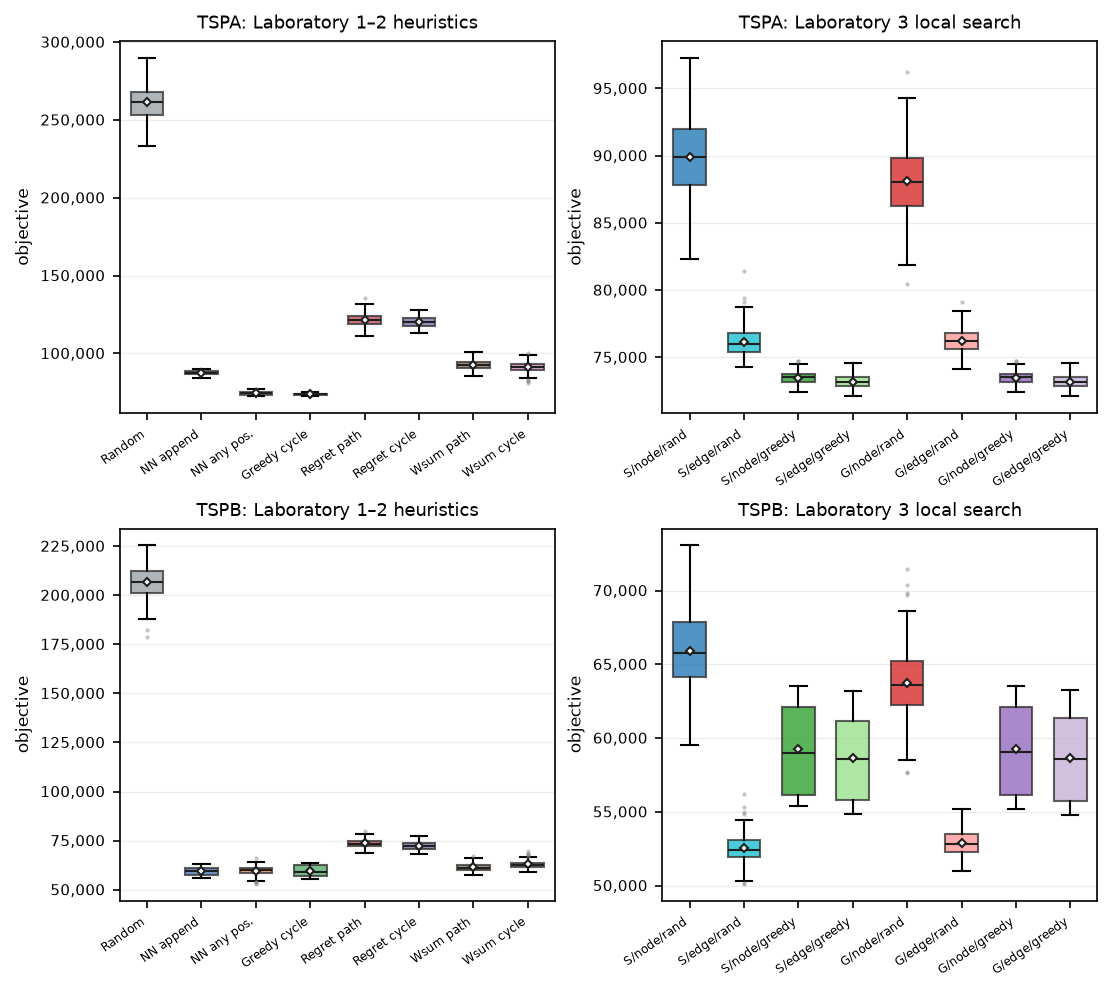

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(7.3, 6.5), layout="constrained")
groups = [
    (PREV, "Laboratory 1–2 heuristics"),
    (LS, "Laboratory 3 local search"),
]

for row, name in enumerate(INSTANCES):
    for col, (group, title) in enumerate(groups):
        ax = axes[row, col]
        data = [runs.loc[(runs.instance == name) & (runs.method == m),
                         "objective"].to_numpy() for m in group]
        bp = ax.boxplot(
            data, tick_labels=[SHORT[m] for m in group], widths=0.6,
            patch_artist=True, showmeans=True,
            medianprops=dict(color="#1f1f1f", lw=1.0),
            meanprops=dict(marker="D", markerfacecolor="white",
                           markeredgecolor="#1f1f1f", markersize=3.0),
            flierprops=dict(marker="o", markersize=2.0, markerfacecolor="#8a8a8a",
                            markeredgecolor="none", alpha=0.5),
        )
        for patch, method in zip(bp["boxes"], group):
            patch.set_facecolor(COLORS[method])
            patch.set_alpha(0.78)
            patch.set_edgecolor("#333333")
        ax.set_title(f"{name}: {title}", fontsize=8.5)
        ax.set_ylabel("objective", fontsize=8)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.grid(axis="y", alpha=0.25, lw=0.6)
        ax.set_axisbelow(True)
        ax.set_xticklabels([SHORT[m] for m in group], rotation=35, ha="right",
                           fontsize=5.8)
        ax.tick_params(axis="y", labelsize=7)

fig.savefig(FIG / "distributions.png", bbox_inches="tight")
plt.show()

The distributions separate into three groups: the random heuristic (far right
and very wide), the regret/weighted heuristics (also wide), and the local-search
methods (narrow and low). Among the local-search methods, the edge-exchange
variants are clearly better than the node-exchange variants, and the
greedy-start edge-exchange methods produce the tightest TSPA distribution. On
TSPB the random-start edge-exchange method is remarkably strong: its whole
distribution lies below the greedy-start distributions.


### 5.4 Random search with an equal time budget

To check whether random sampling can compensate for the absence of local
search, the random heuristic was repeated until its running time approximately matched
the average running time of the eight local-search methods. A pilot run estimates
the number of random restarts; the final time and the best random objective are
then measured on a fresh run with a different seed. Within a run, every restart
draws a new random tour from the advancing stream.



In [7]:
import tempfile

def run_random(n, seed):
    with tempfile.TemporaryDirectory() as tmp:
        with contextlib.redirect_stdout(io.StringIO()):
            rc.run_solver("all", Path(tmp),
                          ["--only", "random", "--runs", str(n),
                           "--seed", str(seed)])
        return pd.read_csv(Path(tmp) / "summary.csv")

budget = (summary[summary.method.isin(LS)]
          .groupby("instance")["time_ms"].mean() / RUNS)
PILOT = 10000
pilot = run_random(PILOT, SEED + 1)
pilot_ms = pilot.groupby("instance")["time_ms"].mean()

random_rows = []
for k, name in enumerate(INSTANCES):
    n = max(1, round(PILOT * budget[name] / pilot_ms[name]))
    rs = run_random(n, SEED + 101 + k)
    r = rs[rs.instance == name].iloc[0]
    best_ls = summary[(summary.instance == name) & summary.method.isin(LS)]
    random_rows.append({
        "Instance": name,
        "Budget ms": f"{budget[name]:.2f}",
        "Restarts": f"{n:,}",
        "Random ms": f"{r['time_ms']:.2f}",
        "Best random": f"{int(r['min']):,}",
        "Best LS avg": f"{best_ls['average'].min():,.1f}",
        "Best LS single": f"{int(best_ls['best'].min()):,}",
    })

random_budget = pd.DataFrame(random_rows).set_index("Instance")
display(random_budget)


,Budget ms,Restarts,Random ms,Best random,Best LS avg,Best LS single
Instance,,,,,,
TSPA,6.17,"3,054",6.00,"225,062","73,170.4","72,088"
TSPB,6.38,"3,190",6.30,"177,962","52,513.6","50,109"


Even with several thousand random restarts, the best random objective remains
far above the local-search results on both instances. Random sampling does not
compensate for the lack of neighbourhood search within the same time budget.



## 6. Best solutions

Each panel shows the best cycle found by one local-search variant. Grey dots are nodes that
were **not** selected. Selected nodes are drawn with a colour **and** a radius
that both encode the node cost (dark purple, small = cheap; yellow, large =
expensive). Thin arrows show the direction of travel along the cycle.


In [8]:
CMAP = plt.get_cmap("viridis")

def load_tour(name, method):
    row = tours[(tours.instance == name) & (tours.method == method)].iloc[0]
    return np.array([int(v) for v in str(row["tour"]).split()]), row

def draw(ax, name, method, norm, short=True):
    df = COORDS[name]
    tour, row = load_tour(name, method)
    sel = np.zeros(len(df), dtype=bool)
    sel[tour] = True
    x = df.x.to_numpy()
    y = df.y.to_numpy()
    cost = df.cost.to_numpy()

    ax.scatter(x[~sel], y[~sel], s=5, c="#d4d4d4", linewidths=0, zorder=1)
    for i in range(len(tour)):
        a, b = tour[i], tour[(i + 1) % len(tour)]
        ax.annotate("", xy=(x[b], y[b]), xytext=(x[a], y[a]),
                    arrowprops=dict(arrowstyle="-|>", color="#555555", lw=0.42,
                                    shrinkA=2.0, shrinkB=3.0, mutation_scale=5,
                                    alpha=0.75),
                    zorder=2)
    t = (cost[tour] - norm.vmin) / max(1e-9, norm.vmax - norm.vmin)
    ax.scatter(x[tour], y[tour], s=7 + 42 * t, c=cost[tour], cmap=CMAP,
               norm=norm, edgecolors="#1b1b1b", linewidths=0.35, zorder=3)

    label = SHORT[method] if short else LABELS[method]
    ax.set_title(f"{label}\nobjective {nf(row['objective'])}",
                 fontsize=7.0 if short else 8.2, pad=3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#dcdcdc")

def best_figure(name):
    norm = mpl.colors.Normalize(*COST_RANGE[name])
    ncol = 2
    nrow = (len(LS) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.3, 2.35 * nrow),
                             layout="constrained")
    axes = np.atleast_1d(axes).ravel()
    for ax, method in zip(axes, LS):
        draw(ax, name, method, norm, short=False)
    for ax in axes[len(LS):]:
        ax.axis("off")
    fig.suptitle(f"{name}: best solution for each local-search variant", fontsize=11)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=list(axes), fraction=0.022, pad=0.015)
    cb.set_label("node cost", fontsize=7.5)
    cb.ax.tick_params(labelsize=6.5)
    fig.savefig(FIG / f"best_{name}.png", bbox_inches="tight")
    plt.show()

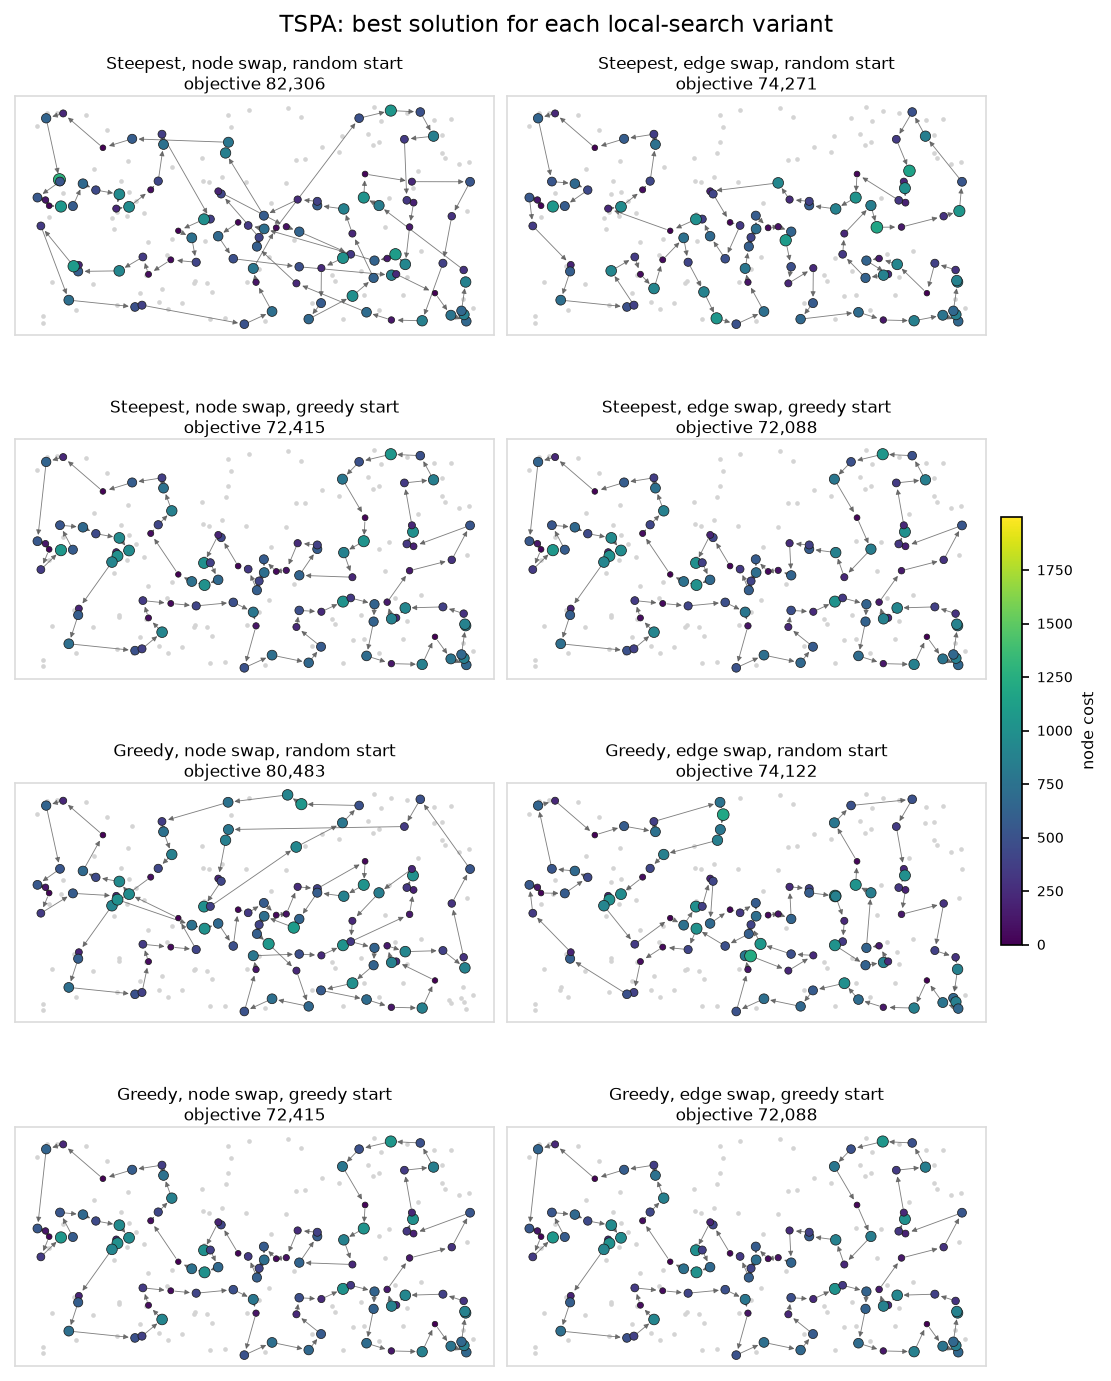

In [9]:
best_figure("TSPA")

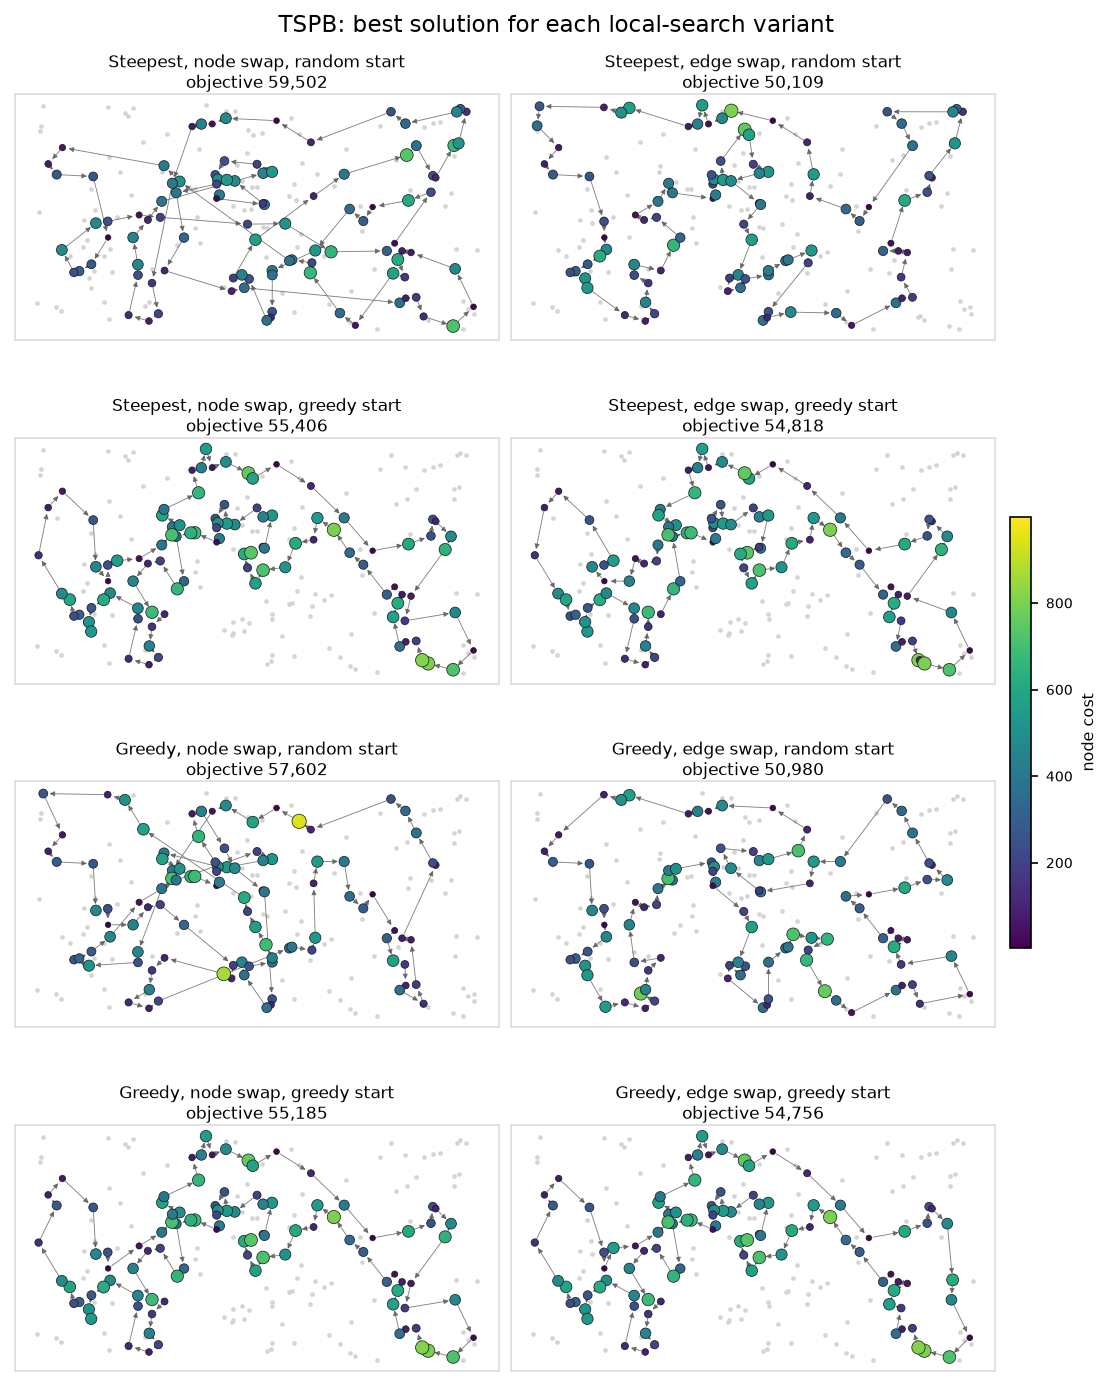

In [10]:
best_figure("TSPB")

## 7. Best solutions as node lists

All indices are **0-based**; the list is the cycle order and the closing arc runs
from the last node back to the first one. The objective, distance and node-cost
components are reported with each tour. A column-wise version of all tours is
included with the results for direct spreadsheet use. Every tour visits exactly
`k` distinct nodes.


In [11]:
for name in INSTANCES:
    print(name)
    for method in METHODS:
        _, row = load_tour(name, method)
        idx = str(row["tour"]).split()
        print(f"\n{LABELS[method]} — objective {nf(row['objective'])} "
              f"(distance {nf(row['distance'])}, costs {nf(row['costs'])}), "
              f"first node {int(row['first_node'])}:")
        for i in range(0, len(idx), 16):
            print("  " + " ".join(idx[i:i + 16]))
    print()

TSPA

Random — objective 233,290 (distance 134,993, costs 98,297), first node 111:
  111 151 38 99 54 39 174 144 1 133 30 55 101 180 2 68
  102 83 80 154 104 175 186 120 60 185 74 62 198 132 196 22
  94 44 173 27 110 187 170 193 124 50 197 150 56 98 25 191
  35 143 65 112 137 20 8 90 49 113 67 66 12 37 24 166
  135 48 79 82 63 45 123 189 78 4 157 36 10 167 141 127
  41 84 40 73 96 139 59 195 0 70 184 43 19 178 34 18
  69 53 95 164

NN (append at end) — objective 84,362 (distance 31,319, costs 53,043), first node 54:
  54 9 33 36 177 67 144 53 135 58 134 176 174 106 89 107
  57 182 151 93 50 3 1 164 178 29 136 186 184 47 159 130
  153 78 88 193 170 146 75 64 150 42 113 43 85 142 8 131
  84 158 192 181 114 141 180 132 76 80 48 31 63 149 168 97
  127 187 30 123 152 108 60 116 49 11 119 160 83 90 51 16
  35 87 45 140 52 179 185 28 102 156 157 71 91 38 100 4
  112 139 115 5

NN (any position) — objective 72,328 (distance 21,816, costs 50,512), first node 104:
  104 129 69 127 97 168 116 149

## 8. Conclusions


**Discussion.** The results show three consistent patterns.

First, the intra-route move is the most important design choice. The best
edge-exchange variants are clearly better than the best node-exchange variants
on both instances, because a 2-opt move can remove a long detour in a single
step while a node exchange only relocates two selected points.

Second, the starting solution determines how much local search can gain. From
the greedy cycle the improvement is small in relative terms, but the resulting
tours are the best on TSPA. From a random start the objective improves
dramatically, but the search usually ends in a worse local optimum on TSPA; on
TSPB the random-start edge search is better than the greedy-start one. A strong
constructive start can therefore lead the search into a local optimum from
which the neighbourhood cannot escape.

Third, steepest and greedy scanning reach almost the same final objective, but
greedy is much faster in wall-clock time from random starts. It evaluates far
fewer deltas because it stops at the first improving move, while steepest scans
the whole neighbourhood in every iteration. The lazy Fisher-Yates shuffle keeps
the randomization cost proportional to the number of visited moves. From the
greedy cycle both searches are close in time because only a few moves remain;
greedy still evaluates fewer deltas. The best overall averages are obtained by
greedy edge exchange from the greedy cycle on TSPA and by steepest edge exchange
from random starts on TSPB.
